In [2]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 376.6 kB/s eta 0:00:21
   -- ------------------------------------- 0.5/8.4 MB 376.6 kB/s eta 0:00:21
   -- ------------------------------------- 0.5/8.4 MB 376.6 kB/s eta 0:00:21
   -- ------------------------------------- 0.5/8.4 MB 376.6 kB/s eta 0:00:21
   --- ------------------------------------ 0.8/8.4 MB 346.8 kB/s eta 0:00:22
   --- ------------------------------------ 0.8/8.4 MB 346.8 kB/s eta 0:00:22
   --- ------------------------------------ 0.8/8.4 MB 346.8 kB/s eta 0:00:22
   --- ------------------------------------ 0.8/8.4 MB 346.8 kB/s eta 0:00:22
   --- ------------------------


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder

In [5]:
data = pd.read_csv(r"C:\Users\WINDOWS 11\Desktop\Jupyter Notebook\other stuff\Dataset\customer_data.csv")
data.head()

,Age,EstimatedSalary,Purchased
0,19,19000,No
1,35,20000,No
2,26,43000,No
3,27,57000,No
4,19,76000,No


In [6]:
data.Purchased.value_counts()

Purchased
No     15
Yes    12
Name: count, dtype: int64

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              27 non-null     int64
 1   EstimatedSalary  27 non-null     int64
 2   Purchased        27 non-null     str  
dtypes: int64(2), str(1)
memory usage: 846.0 bytes


In [8]:
#Task - Prepare a linear SVC model to predict a new customer purchased based on this data


In [11]:
import warnings
warnings.filterwarnings('ignore')

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

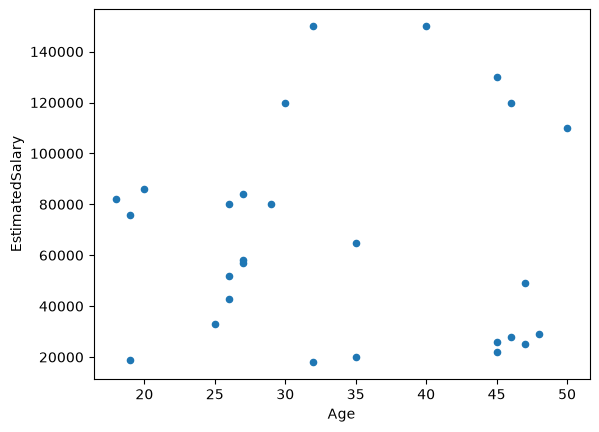

In [13]:
data.plot(kind = 'scatter',x = 'Age',y = 'EstimatedSalary')

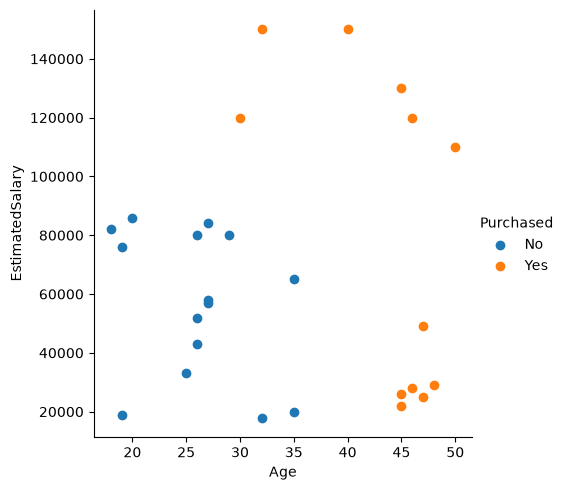

In [15]:
sns.FacetGrid(data,hue = 'Purchased',height = 5).map(plt.scatter,'Age','EstimatedSalary').add_legend()
plt.show()

In [19]:
#time to Encode No and YES present in the data but first data alag and label alag
X = data.drop(['Purchased'],axis = 1)
y = data['Purchased']
X.head()
y.head()

0    No
1    No
2    No
3    No
4    No
Name: Purchased, dtype: str

In [25]:
#now encode y
#always create a copy database
encoder = LabelEncoder()  #lABEL ENCODER IS A CLASS Hence create  an instance of it first
y_enc = encoder.fit_transform(y)
#y_enc is a numpy array and does not have any attribute as head()

In [26]:

# formal way ( for mutiple categorcial columns)
X_train,X_test,y_train,y_test = train_test_split(X,y_enc,test_size = 0.2,random_state = 42)
X_train.head()

,Age,EstimatedSalary
16,47,25000
17,45,26000
12,20,86000
24,46,120000
1,35,20000


In [27]:
svc = SVC()
model = svc.fit(X_train,y_train)

In [28]:
test_score = model.score(X_test,y_test)
training_score = model.score(X_train,y_train)
print(f"The test score is {test_score}\nThe training score is {training_score}") 

The test score is 0.3333333333333333
The training score is 0.9523809523809523


In [29]:
model.predict(X_test)

array([1, 1, 0, 0, 1, 0])

In [30]:
y_test

array([0, 0, 0, 1, 0, 0])

In [31]:
# see the results are actually very bad 
#we need to change the type of kernel to rbf


In [32]:
#ONE THING CRUCIAL IS TO SCALE THE Features since EstimatedSalary and Age differs a large on scale
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)
#again do the following split
X_train,X_test,y_train,y_test = train_test_split(X_scale,y_enc,test_size = 0.2,random_state = 42)

In [36]:
#make madel,fit model
final_model = SVC(kernel = 'rbf',random_state = 42)
final_model.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [37]:
test_score = final_model.score(X_test,y_test)
training_score = final_model.score(X_train,y_train)
print(f"The test score is {test_score}\nThe training score is {training_score}") 

The test score is 1.0
The training score is 1.0


In [38]:
final_model.predict(X_test)

array([0, 0, 0, 1, 0, 0])

In [39]:
y_test

array([0, 0, 0, 1, 0, 0])

In [40]:
#HENCE scaling and RBF IMPORVED THE ACCURACY TO 100%